# Chapitre 12 - Cours 1 : intégration de données

Le dernier chapitre du livre, *The Future of Data Systems*, change de ton : après avoir décrit l'existant, l'auteur propose sa vision de la manière dont les systèmes de données devraient être conçus, en s'appuyant surtout sur les flux d'événements du chapitre précédent. Le chapitre est plus engagé que les autres : il défend une approche plutôt qu'il n'en compare plusieurs.
Ce premier notebook couvre la section *Data Integration* : comment faire cohabiter
plusieurs outils spécialisés qui contiennent **les mêmes données sous des formes
différentes**, sans qu'ils finissent par se contredire.

**Plan.**

1. Combiner des outils spécialisés en dérivant des données.
2. Raisonner sur les flux : un seul ordre pour toutes les écritures.
3. Données dérivées contre transactions distribuées.
4. Les limites de l'ordre total.
5. Ordonner les événements pour capturer la causalité.
6. Maintenir un état dérivé et retraiter les données.
7. L'architecture lambda, et unifier traitements par lots et flux.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
SHARDS = "partitions"   # vocabulaire de l'édition

## 1. Combiner des outils spécialisés en dérivant des données (section *Combining Specialized Tools by Deriving Data*)

Le fil rouge du livre est qu'il n'existe **pas de solution unique** : pour stocker puis
retrouver des données, on a vu des journaux et LSM-trees, des B-trees, du stockage en
colonnes (chapitre 3) ; pour répliquer, un leader, plusieurs, ou aucun
(chapitre 5). Un logiciel donné choisit **une** approche et l'optimise ;
même une base dite « généraliste » est conçue pour un certain profil d'usage. Une
application réelle a plusieurs profils d'usage, donc finit par **combiner plusieurs
outils**.

L'exemple canonique : une base transactionnelle (OLTP) pour les écritures et la vérité,
plus un **index de recherche plein texte** pour les requêtes par mots-clés. Certaines
bases (PostgreSQL) savent faire de la recherche plein texte simple, mais un vrai moteur
de recherche fait mieux ; à l'inverse, un index de recherche est un mauvais système de
référence durable. Et la liste s'allonge vite : entrepôt de données, caches et vues
dénormalisées, modèles d'apprentissage et de recommandation, notifications...

Le livre propose de penser ce paysage comme un **graphe de dérivation** : un seul
**système de référence** (system of record) reçoit les écritures, et chaque autre
représentation est une **donnée dérivée**, recalculable à partir de lui (distinction posée dans l'introduction de la partie III du livre).

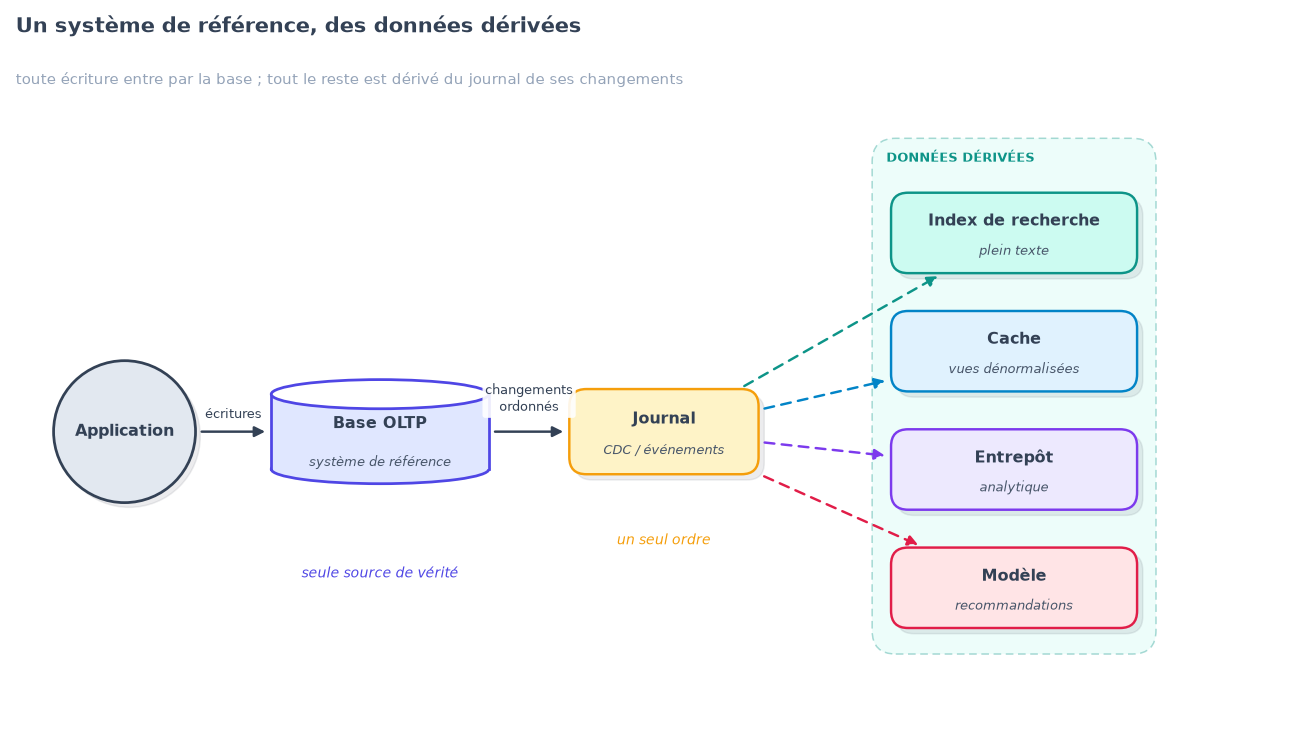

In [2]:
d = Diagram(13.5, 6.6, title="Un système de référence, des données dérivées",
            subtitle="toute écriture entre par la base ; tout le reste est dérivé du journal de ses changements")
d.box("app", 1.2, 3.1, "Application", kind="user", w=1.5, color=SLATE)
d.box("db", 3.9, 3.1, "Base OLTP", sub="système de référence", kind="db", color=INDIGO, w=2.3, h=1.1)
d.box("log", 6.9, 3.1, "Journal", sub="CDC / événements", color=AMBER, w=2.0, h=0.9)
targets = [("idx", "Index de recherche", "plein texte", TEAL, 5.2),
           ("cache", "Cache", "vues dénormalisées", SKY, 3.95),
           ("dwh", "Entrepôt", "analytique", VIOLET, 2.7),
           ("ml", "Modèle", "recommandations", ROSE, 1.45)]
for name, txt, sub, c, y in targets:
    d.box(name, 10.6, y, txt, sub=sub, color=c, w=2.6, h=0.85)
    d.arrow("log", name, style="dashed", color=c)
d.arrow("app", "db", "écritures")
d.arrow("db", "log", "changements\nordonnés", label_offset=(0, 0.35))
d.group(9.1, 0.75, 12.1, 6.2, "données dérivées", color=TEAL)
d.note(3.9, 1.6, "seule source de vérité", color=INDIGO)
d.note(6.9, 1.95, "un seul ordre", color=AMBER)
d.show()

**Pourquoi un journal central plutôt que des connexions point à point ?** Sans
discipline, chaque nouveau système est relié à plusieurs autres par des scripts de
synchronisation ad hoc. Avec $n$ systèmes, il peut y avoir jusqu'à $n(n-1)/2$
intégrations à écrire, tester et surveiller ; avec un journal central, chaque système
n'a qu'**un** connecteur (il publie ou consomme).

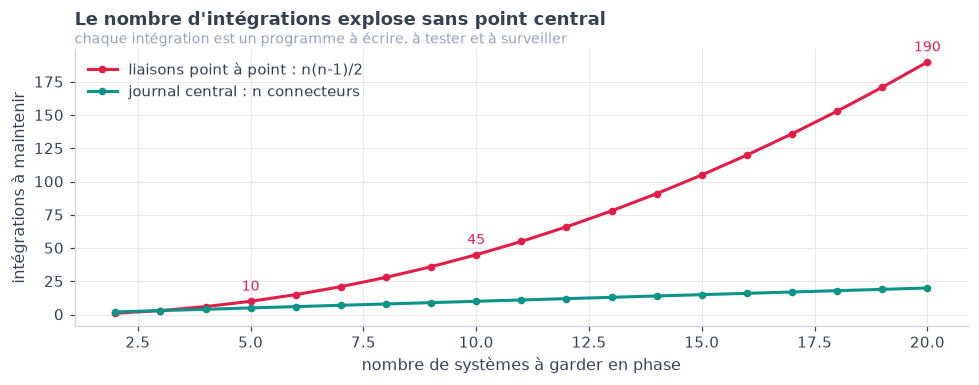

In [3]:
n = np.arange(2, 21)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(n, n * (n - 1) / 2, color=ROSE, marker="o", ms=4, label="liaisons point à point : n(n-1)/2")
ax.plot(n, n, color=TEAL, marker="o", ms=4, label="journal central : n connecteurs")
for k in (5, 10, 20):
    ax.annotate(f"{k * (k - 1) // 2}", (k, k * (k - 1) / 2), (0, 7), textcoords="offset points",
                ha="center", fontsize=9, color=ROSE)
ax.set_xlabel("nombre de systèmes à garder en phase"); ax.set_ylabel("intégrations à maintenir")
ax.set_title("Le nombre d'intégrations explose sans point central")
subtitle(ax, "chaque intégration est un programme à écrire, à tester et à surveiller")
ax.legend(); plt.tight_layout(); plt.show()

> **À retenir.** Aucun outil ne sert bien tous les profils d'accès : on en combine
> plusieurs. Pour garder la maîtrise, on désigne **un** système de référence et on
> considère tout le reste comme des **données dérivées**, alimentées par un flux de
> changements.

## 2. Raisonner sur les flux : un seul ordre pour toutes les écritures (section *Reasoning about dataflows*)

Quand plusieurs systèmes contiennent les mêmes données, il faut savoir répondre à
deux questions : **où une donnée est-elle écrite en premier** ? et **quelle
représentation dérive de quelle source** ? La réponse saine : on écrit d'abord dans la
base de référence, on capture ses changements (capture de changements, CDC, chapitre
11) et on les applique **dans le même ordre** à l'index. Si le CDC est le seul
chemin qui modifie l'index, l'index est entièrement dérivé de la base et donc cohérent
avec elle (aux bogues près).

Le contre-exemple, déjà vu au chapitre 11, est la **double écriture** :
l'application écrit elle-même dans la base **et** dans l'index. Deux clients qui
modifient la même clé presque en même temps peuvent voir leurs écritures arriver dans
un ordre différent dans chaque système. Personne n'est « responsable » de l'ordre, et
les deux systèmes divergent **définitivement**.

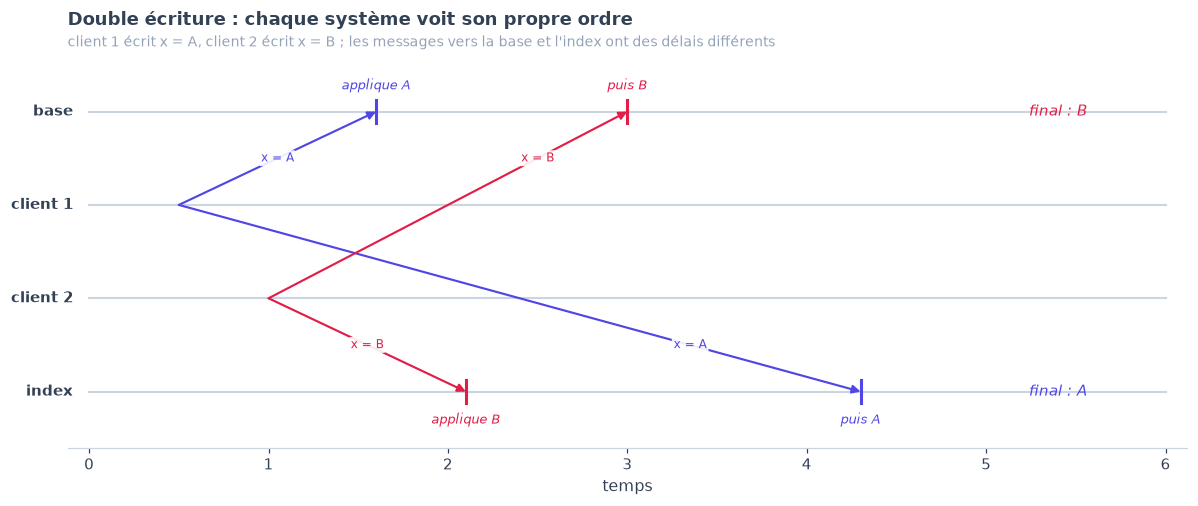

In [4]:
st = SpaceTime(["base", "client 1", "client 2", "index"], t_max=6, width=11,
               title="Double écriture : chaque système voit son propre ordre",
               subtitle="client 1 écrit x = A, client 2 écrit x = B ; les messages vers la base et l'index ont des délais différents")
st.msg("client 1", 0.5, "base", 1.6, "x = A", color=INDIGO)
st.msg("client 1", 0.5, "index", 4.3, "x = A", color=INDIGO, label_pos=0.75)
st.msg("client 2", 1.0, "base", 3.0, "x = B", color=ROSE, label_pos=0.75)
st.msg("client 2", 1.0, "index", 2.1, "x = B", color=ROSE)
for node, t, c in [("base", 1.6, INDIGO), ("base", 3.0, ROSE), ("index", 2.1, ROSE), ("index", 4.3, INDIGO)]:
    st.event(node, t, kind="tick", color=c)
st.note(1.6, "base", "applique A", dy=0.28, color=INDIGO)
st.note(3.0, "base", "puis B", dy=0.28, color=ROSE)
st.note(2.1, "index", "applique B", dy=-0.3, color=ROSE)
st.note(4.3, "index", "puis A", dy=-0.3, color=INDIGO)
st.note(5.4, "base", "final : B", dy=0.0, color=ROSE, fontsize=10)
st.note(5.4, "index", "final : A", dy=0.0, color=INDIGO, fontsize=10)
st.show()

**Quantifions.** Modélisons chaque délai réseau par une constante plus une variable
exponentielle de moyenne $j$ (la gigue), et notons $g$ l'écart entre les deux écritures.
Dans un système donné, l'écriture A (la plus ancienne) arrive **après** B si son délai
dépasse celui de B d'au moins $g$. La différence de deux exponentielles indépendantes
suit une loi de Laplace, d'où

$$p = P(\text{A arrive après B}) = \tfrac12\, e^{-g/j}, \qquad
  P(\text{divergence}) = 2\,p\,(1-p),$$

car les deux systèmes divergent quand l'un garde A et l'autre B. Comparons avec la
simulation (`dfl.dual_write_divergence`), et avec la variante où les deux écritures
passent d'abord par un **journal** dont l'ordre fait foi.

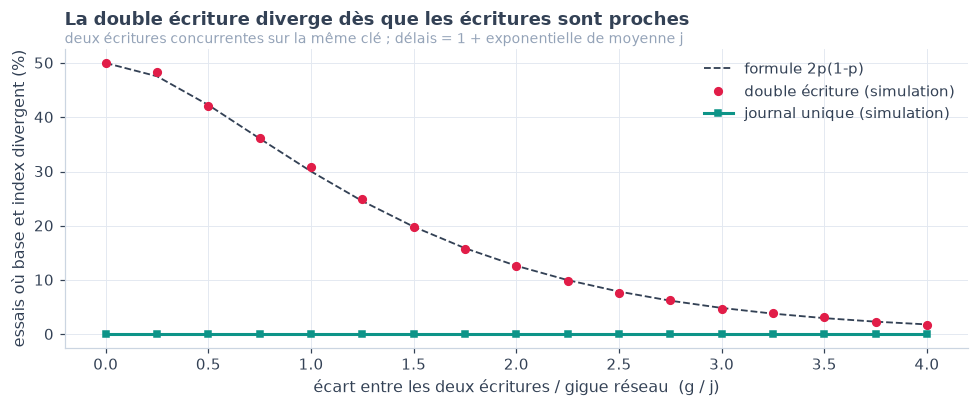

In [5]:
ratios = np.linspace(0, 4, 17)
sim = [dfl.dual_write_divergence(r, 1.0, n_trials=20_000, seed=i) for i, r in enumerate(ratios)]
via_log = [dfl.dual_write_divergence(r, 1.0, n_trials=5_000, seed=i, via_log=True) for i, r in enumerate(ratios)]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(ratios, [dfl.dual_write_divergence_formula(r, 1.0) * 100 for r in ratios], color=SLATE, lw=1.2,
        ls="--", label="formule 2p(1-p)")
ax.plot(ratios, np.array(sim) * 100, "o", color=ROSE, ms=5, label="double écriture (simulation)")
ax.plot(ratios, np.array(via_log) * 100, "s-", color=TEAL, ms=4, label="journal unique (simulation)")
ax.set_xlabel("écart entre les deux écritures / gigue réseau  (g / j)")
ax.set_ylabel("essais où base et index divergent (%)")
ax.set_title("La double écriture diverge dès que les écritures sont proches")
subtitle(ax, "deux écritures concurrentes sur la même clé ; délais = 1 + exponentielle de moyenne j")
ax.legend(); plt.tight_layout(); plt.show()

Pour deux écritures simultanées ($g = 0$), la divergence touche **la moitié** des cas ;
elle reste de 21 % pour un écart égal à la gigue, et de 3,6 % pour un écart de trois
fois la gigue. À l'échelle de millions d'écritures par jour, même la queue de la
courbe produit des incohérences quotidiennes. Avec un journal unique, le taux est
**nul** : l'ordre de la course est tranché une fois pour toutes, au moment de l'ajout
au journal, et tous les consommateurs l'appliquent dans le même ordre. C'est le
principe de la **réplication par machine à états** (chapitre 9) : peu
importe qu'il s'agisse de CDC ou d'un journal d'événements (event sourcing), l'essentiel
est de **décider d'un ordre total**.

**Déterminisme et idempotence.** Une mise à jour dérivée d'un journal peut souvent être
rendue **déterministe** (même journal, même résultat) et **idempotente** (rejouer une
entrée déjà appliquée ne change rien). Vérifions-le : rejouons un journal de changements
deux fois, puis avec des entrées dupliquées, et comparons l'index obtenu.

In [6]:
rng = random.Random(7)
changes = [("put", rng.randrange(40), rng.choice(["rouge", "vert", "bleu", "noir"])) for _ in range(300)]
ref = dfl.index_from_table(dfl.replay_table(changes))
b1 = dfl.IndexBuilder(); b1.catch_up(changes)
b2 = dfl.IndexBuilder(); b2.catch_up(changes)
dup = []
for c in changes:                        # livraison « au moins une fois » : 20 % de doublons consécutifs
    dup.append(c)
    if rng.random() < 0.2:
        dup.append(c)
b3 = dfl.IndexBuilder(); b3.catch_up(dup)
pd.DataFrame({"index obtenu": ["rejeu 1", "rejeu 2", "rejeu avec doublons"],
              "identique à la référence": [b1.as_dict() == ref, b2.as_dict() == ref, b3.as_dict() == ref],
              "entrées appliquées": [b1.applied, b2.applied, b3.applied]})

,index obtenu,identique à la référence,entrées appliquées
0,rejeu 1,True,300
1,rejeu 2,True,300
2,rejeu avec doublons,True,359


Les trois index sont identiques à la référence : une opération « mettre la clé $k$ à la
valeur $v$ » est naturellement idempotente quand les doublons arrivent **à la suite**.
Attention : ce ne serait plus vrai si un doublon tardif réapparaissait après une écriture
plus récente de la même clé, ni pour une opération « ajouter 1 » ; il faudrait alors
mémoriser les offsets ou identifiants déjà appliqués (sections 2 et 6 du cours 4).
C'est cette propriété qui rend la **reprise après panne** si simple : un consommateur
repart de son dernier offset et rejoue.

> **À retenir.** Laisser l'application écrire dans plusieurs systèmes revient à laisser
> chaque système choisir son ordre : ils divergent avec une probabilité qui devient
> énorme pour des écritures proches. Faire passer toutes les écritures par **un** journal
> ordonné, puis dériver les autres représentations dans cet ordre, rend la cohérence
> automatique et la reprise triviale.

## 3. Données dérivées contre transactions distribuées (section *Derived data versus distributed transactions*)

L'approche classique pour garder plusieurs systèmes cohérents est la **transaction
distribuée** (validation en deux phases, 2PC, chapitre 7). Les deux
approches visent le même but par des moyens différents :

| | transaction distribuée (2PC, XA) | données dérivées par journal |
|---|---|---|
| mécanisme de justesse | validation atomique | rejeu déterministe et idempotence |
| ordre | verrous (sérialisation des écritures) | ordre du journal |
| lire ses propres écritures | oui, immédiatement | non par défaut (mise à jour asynchrone) |
| panne d'un participant | bloque ou annule **toutes** les écritures | le consommateur prend du retard, puis rattrape |
| intégration hétérogène | difficile (XA peu tolérant aux pannes et lent) | simple : lire un journal et appliquer |

La différence décisive concerne les pannes. Une transaction distribuée a besoin que
**tous** les participants répondent : sa disponibilité est le produit des
disponibilités, et une panne locale devient une panne globale. Avec un journal, la
panne d'un système dérivé ne fait que **retarder** sa mise à jour. Simulons trois mois
avec une base et quatre systèmes dérivés, chacun tombant en panne en moyenne tous les
cinq jours pendant une heure (`dfl.sync_vs_async`) ; un système dérivé qui revient
rattrape son retard à trois fois le débit d'écriture.

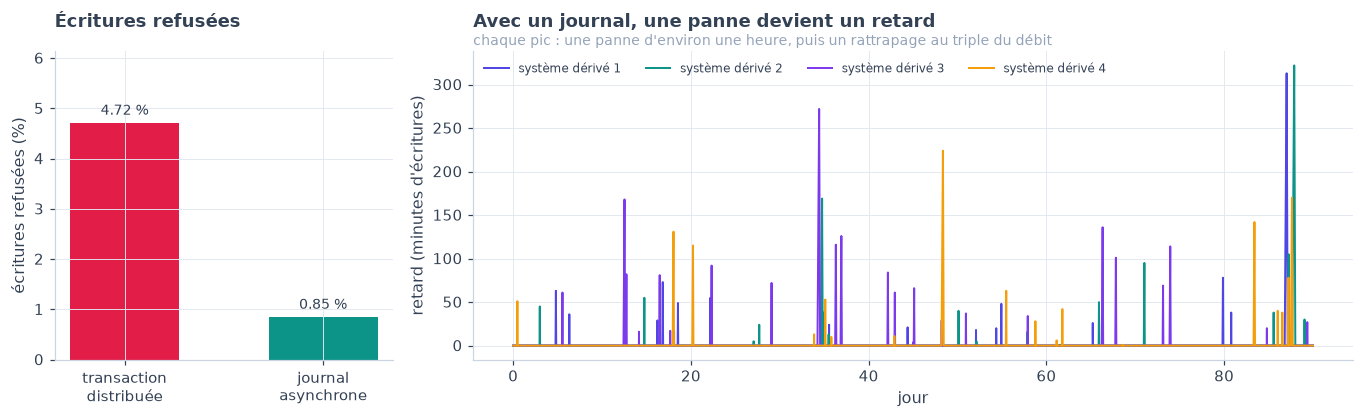

disponibilité en écriture : 2PC 95.28 %, journal 99.15 % ; retard max d'un système dérivé : 322 min


In [7]:
res = dfl.sync_vs_async(n_derived=4, n_steps=90 * 24 * 60, mtbf=5 * 24 * 60, mttr=60, catch_up=3.0, seed=2)
lag_h = res["lag"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1, 2.6]})
vals = [res["sync_refused"] * 100, res["async_refused"] * 100]
ax1.bar(["transaction\ndistribuée", "journal\nasynchrone"], vals, color=[ROSE, TEAL], width=0.55)
annotate_bars(ax1, "{:.2f} %")
ax1.set_ylim(0, max(vals) * 1.3); ax1.set_ylabel("écritures refusées (%)")
ax1.set_title("Écritures refusées")
days = np.arange(lag_h.shape[1]) / (24 * 60)
for i, c in enumerate([INDIGO, TEAL, VIOLET, AMBER]):
    ax2.plot(days, lag_h[i], color=c, lw=1.3, label=f"système dérivé {i + 1}")
ax2.set_xlabel("jour"); ax2.set_ylabel("retard (minutes d'écritures)")
ax2.set_title("Avec un journal, une panne devient un retard")
subtitle(ax2, "chaque pic : une panne d'environ une heure, puis un rattrapage au triple du débit")
ax2.legend(ncol=4, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
print(f"disponibilité en écriture : 2PC {100 - vals[0]:.2f} %, journal {100 - vals[1]:.2f} % ; "
      f"retard max d'un système dérivé : {lag_h.max():.0f} min")

Chaque composant est indisponible en moyenne $60 / (7\,200 + 60) \approx 0{,}8$ % du
temps. La transaction distribuée a besoin des cinq : $1 - 0{,}992^5 \approx 4$ % de refus
attendus (4,7 % dans cette simulation), soit environ **cinq fois plus** que le journal,
qui ne dépend que de la base (0,85 %). En contrepartie, chaque système dérivé accuse un
**retard** après chacune de ses pannes : une heure de panne laisse une heure de retard,
résorbée en trente minutes (le rattrapage gagne deux minutes d'écritures par minute),
et la panne la plus longue du trimestre laisse ici plus de cinq heures de retard.
Pendant ce temps, l'index ou le cache sert des données périmées. Le livre ne prétend pas que ce retard est gratuit : des garanties
comme « lire ses propres écritures » restent précieuses, et dire aux développeurs « la
cohérence à terme est inévitable, débrouillez-vous » n'est pas une réponse. Les cours
4 et 5 montrent comment obtenir des garanties fortes **au-dessus** de systèmes dérivés
asynchrones.

> **À retenir.** La transaction distribuée et le journal visent tous deux des systèmes
> cohérents. La première **propage** les pannes (disponibilité = produit des
> disponibilités) ; le second les **contient** (une panne devient un retard), au prix de
> lectures parfois périmées. Faute d'un bon protocole de transaction distribuée largement
> adopté, le journal est l'approche la plus prometteuse pour intégrer des systèmes
> hétérogènes.

## 4. Les limites de l'ordre total (section *The limits of total ordering*)

Un journal totalement ordonné est facile à construire pour un système de taille
modeste : c'est exactement ce que fait une base à leader unique. Mais l'ordre total se
heurte à quatre limites quand le système grandit :

| situation | pourquoi l'ordre total disparaît |
|---|---|
| débit trop élevé pour une machine | il faut répartir le journal en partitions ; l'ordre entre deux partitions est indéfini |
| plusieurs centres de données | un leader par centre (la coordination synchrone à distance est trop lente) ; deux événements nés dans deux centres n'ont pas d'ordre |
| microservices | chaque service a son propre état durable ; deux services n'ont pas d'ordre commun |
| clients avec état local, hors ligne | le client applique l'action tout de suite ; client et serveur voient les événements dans des ordres différents |

Formellement, décider d'un ordre total est la **diffusion à ordre total** (total order
broadcast), équivalente au **consensus** (chapitre 9) ; or les algorithmes
de consensus supposent qu'un seul nœud peut traiter tout le flux, et ne savent pas
partager le travail d'ordonnancement entre plusieurs nœuds.

**Combien d'ordres globaux sont compatibles avec les ordres locaux ?** Avec $k$
partitions contenant chacun $n$ événements ordonnés, tout entrelacement qui
respecte l'ordre interne de chaque partition est un ordre global possible : il y en a
$(kn)! / (n!)^k$. Un consommateur qui lit plusieurs partitions voit **l'un** d'eux, et deux
consommateurs peuvent en voir deux différents.

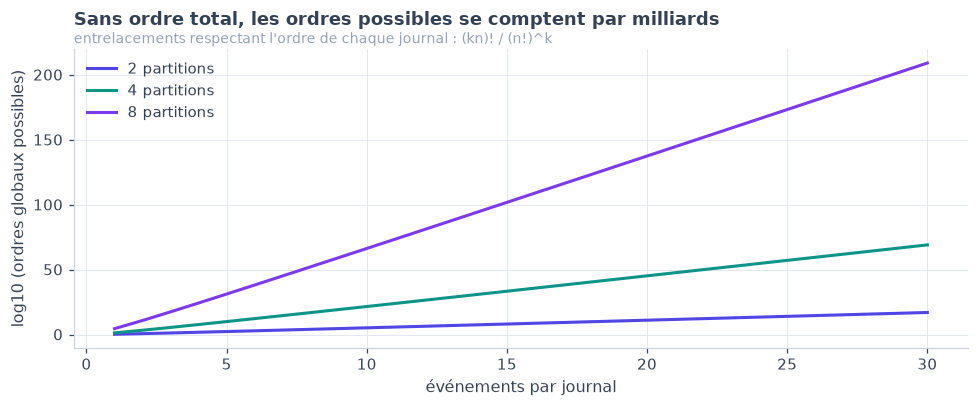

2 journaux de 10 événements : 184756 ordres globaux possibles


In [8]:
ns = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, c in [(2, INDIGO), (4, TEAL), (8, VIOLET)]:
    logv = [(math.lgamma(k * x + 1) - k * math.lgamma(x + 1)) / math.log(10) for x in ns]
    ax.plot(ns, logv, color=c, label=f"{k} {SHARDS}")
ax.set_xlabel("événements par journal"); ax.set_ylabel("log10 (ordres globaux possibles)")
ax.set_title("Sans ordre total, les ordres possibles se comptent par milliards")
subtitle(ax, "entrelacements respectant l'ordre de chaque journal : (kn)! / (n!)^k")
ax.legend(); plt.tight_layout(); plt.show()
print("2 journaux de 10 événements :", math.comb(20, 10), "ordres globaux possibles")

Deux journaux de dix événements seulement admettent déjà 184 756 ordres globaux. Ce
n'est grave que si l'ordre **compte**, c'est-à-dire si des événements de journaux
différents ont un lien de **causalité**. Les mises à jour d'un même objet se règlent
facilement : on route toutes les écritures d'un identifiant vers le même
partition, et leur ordre est préservé. Les dépendances causales entre objets
différents sont plus sournoises : c'est l'objet de la section suivante.

> **À retenir.** L'ordre total coûte un goulot d'étranglement (un leader, un
> consensus). Dès qu'on partitionnee, qu'on répartit sur plusieurs centres, qu'on découpe
> en services ou qu'on travaille hors ligne, il disparaît : il ne reste qu'un ordre par
> partition. On garde dans un même partition ce qui doit être ordonné.

## 5. Ordonner les événements pour capturer la causalité (section *Ordering events to capture causality*)

Le livre prend un exemple de réseau social. Deux personnes viennent de rompre : l'une
**retire l'autre de ses amis**, puis envoie à ses amis restants un message désobligeant
sur son ex. Son intention est claire : l'ex ne doit pas le voir, puisque le message
est **postérieur** au retrait. Mais si les amitiés et les messages sont stockés dans
deux systèmes différents, le service de notifications (qui fait en réalité une
**jointure** entre messages et listes d'amis, comme les jointures de flux du chapitre
11) peut recevoir le message **avant** le retrait, et notifier l'ex.

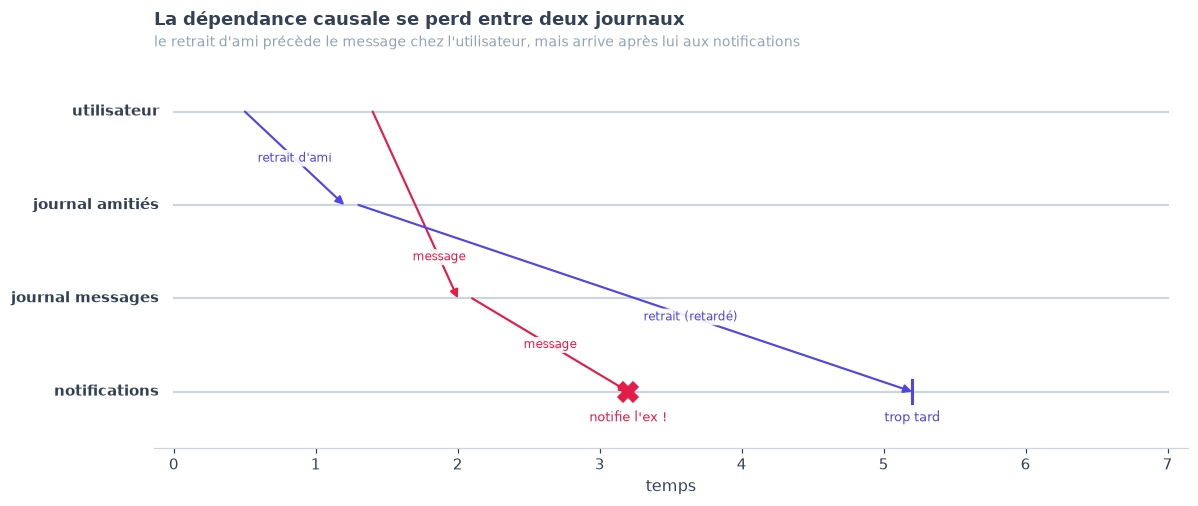

In [9]:
st = SpaceTime(["utilisateur", "journal amitiés", "journal messages", "notifications"], t_max=7, width=11,
               title="La dépendance causale se perd entre deux journaux",
               subtitle="le retrait d'ami précède le message chez l'utilisateur, mais arrive après lui aux notifications")
st.msg("utilisateur", 0.5, "journal amitiés", 1.2, "retrait d'ami", color=INDIGO)
st.msg("utilisateur", 1.4, "journal messages", 2.0, "message", color=ROSE, label_pos=0.78)
st.msg("journal amitiés", 1.3, "notifications", 5.2, "retrait (retardé)", color=INDIGO, label_pos=0.6)
st.msg("journal messages", 2.1, "notifications", 3.2, "message", color=ROSE)
st.event("notifications", 3.2, "notifie l'ex !", kind="crash")
st.event("notifications", 5.2, "trop tard", kind="tick", color=INDIGO)
st.show()

Le problème n'a pas de solution simple ; le livre cite trois pistes :

- des **horodatages logiques** (Lamport, chapitre 9) donnent un ordre total
  sans coordination, mais le destinataire doit encore gérer les événements arrivés dans
  le désordre, et il faut transporter ces métadonnées ;
- **journaliser l'état vu par l'utilisateur** au moment de sa décision, sous un
  identifiant unique, et faire référencer cet identifiant par les événements suivants :
  la dépendance causale devient explicite ;
- des **algorithmes de résolution de conflits** (chapitre 5) aident à
  maintenir un état correct malgré le désordre, mais pas quand l'action a un **effet
  externe** irréversible (envoyer une notification).

Implémentons la deuxième piste : le message porte la **version de la liste d'amis** vue
par l'expéditeur (ici, la version postérieure au retrait), et le service de
notifications **attend** d'avoir appliqué cette version avant de notifier. Mesurons le
taux de fuite sans correctif, et le coût du correctif (attente ajoutée), selon l'écart
entre le retrait et le message (`dfl.unfriend_experiment`).

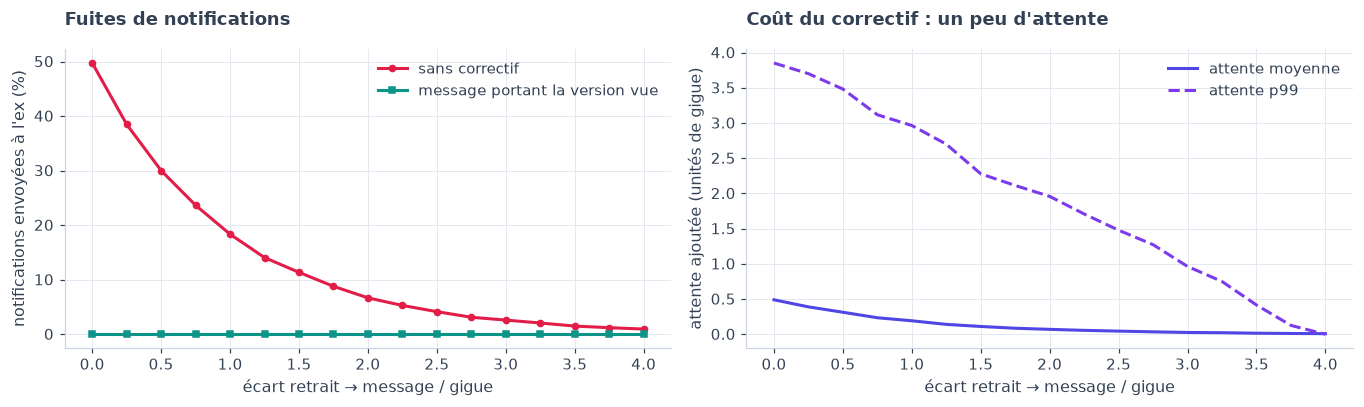

écart nul : fuite 49.7% ; attente moyenne 0.49, p99 3.85


In [10]:
gaps = np.linspace(0, 4, 17)
r = dfl.unfriend_experiment(gaps, jitter=1.0, n_trials=20_000, seed=3)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax1.plot(gaps, r["leak"] * 100, "o-", color=ROSE, ms=4, label="sans correctif")
ax1.plot(gaps, np.zeros_like(gaps), "s-", color=TEAL, ms=4, label="message portant la version vue")
ax1.set_xlabel("écart retrait → message / gigue"); ax1.set_ylabel("notifications envoyées à l'ex (%)")
ax1.set_title("Fuites de notifications"); ax1.legend()
ax2.plot(gaps, r["wait_mean"], color=INDIGO, label="attente moyenne")
ax2.plot(gaps, r["wait_p99"], color=VIOLET, ls="--", label="attente p99")
ax2.set_xlabel("écart retrait → message / gigue"); ax2.set_ylabel("attente ajoutée (unités de gigue)")
ax2.set_title("Coût du correctif : un peu d'attente"); ax2.legend()
plt.tight_layout(); plt.show()
print(f"écart nul : fuite {r['leak'][0]:.1%} ; attente moyenne {r['wait_mean'][0]:.2f}, p99 {r['wait_p99'][0]:.2f}")

Quand le message suit de près le retrait, la notification fuit dans près d'**un cas sur
deux** (même loi de Laplace qu'en section 2). La référence explicite supprime toute
fuite ; le prix est une attente **rare et courte** : en moyenne une demi-unité de gigue
pour un écart nul, et presque rien quand le message est envoyé longtemps après le
retrait. Le livre conclut que des motifs de développement capturant efficacement la
causalité, **sans** faire passer tous les événements par le goulot d'une diffusion à
ordre total, restent à inventer.

> **À retenir.** Sans ordre total, les dépendances causales entre objets différents se
> perdent, et une jointure peut produire un effet externe faux. Rendre la dépendance
> **explicite** (référence à l'état vu par l'utilisateur) la restaure, au prix d'une
> attente ponctuelle.